# EN4554 Assignment 2 : CNNs

**Name:** Indunil W.A.K.  
**Index:** 220240G  
**GitHub:** https://github.com/indunil-k/CNNs_220240G.git  

Test data is reserved for Task 4.

## 0. Setup

We fix seeds, create a fixed 45,000/5,000 split, and compute normalization statistics from the training subset only.

In [2]:
import copy
import random
import time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, Subset
from torchvision import transforms

SEED = 42
NUM_WORKERS = 0  # reliable on both laptops and Colab
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch:', torch.__version__)
print('Device:', device)

COLORS = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
plt.rcParams.update({'axes.grid': True, 'grid.alpha': 0.3, 'axes.spines.top': False,
                     'axes.spines.right': False, 'lines.linewidth': 2, 'figure.dpi': 110})

PyTorch: 2.11.0+cu130
Device: cuda


In [3]:
raw_transform = transforms.ToTensor()
raw_train = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=raw_transform)
generator = torch.Generator().manual_seed(SEED)
permutation = torch.randperm(len(raw_train), generator=generator).tolist()
train_indices = permutation[:45000]
val_indices = permutation[45000:]

stats_loader = DataLoader(Subset(raw_train, train_indices), batch_size=512, shuffle=False, num_workers=NUM_WORKERS)
channel_sum = torch.zeros(3)
channel_squared_sum = torch.zeros(3)
pixel_count = 0
for images, _ in stats_loader:
    images = images.float()
    channel_sum += images.sum(dim=(0, 2, 3))
    channel_squared_sum += (images ** 2).sum(dim=(0, 2, 3))
    pixel_count += images.shape[0] * images.shape[2] * images.shape[3]
mean = channel_sum / pixel_count
std = torch.sqrt(channel_squared_sum / pixel_count - mean ** 2)
print('Training mean:', mean)
print('Training std:', std)
print('Train size:', len(train_indices), 'Validation size:', len(val_indices))

100%|██████████| 170M/170M [23:15<00:00, 122kB/s]  


Training mean: tensor([0.4917, 0.4823, 0.4467])
Training std: tensor([0.2471, 0.2435, 0.2616])
Train size: 45000 Validation size: 5000


In [4]:
normalize = transforms.Normalize(mean=mean.tolist(), std=std.tolist())
transform = transforms.Compose([transforms.ToTensor(), normalize])
train_dataset_full = torchvision.datasets.CIFAR10(root='./data', train=True, download=False, transform=transform)
train_dataset = Subset(train_dataset_full, train_indices)
val_dataset = Subset(train_dataset_full, val_indices)
train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True, num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())
val_loader = DataLoader(val_dataset, batch_size=256, shuffle=False, num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())
print('Setup complete. Test data remains unused until Task 4.')

Setup complete. Test data remains unused until Task 4.


### Setup interpretation

The split is fixed by the seed, so all experiments can be compared fairly. Normalization uses only training statistics, preventing validation or test information from entering preprocessing.

## Task 1: Backpropagation

Every layer is a small module with two methods:

- `forward(x)`: compute the output and **cache** whatever backward will need.
- `backward(grad_out)`: receive $\partial L/\partial \text{output}$, store the parameter gradients, and return $\partial L/\partial \text{input}$.

Backpropagation is the chain rule applied layer by layer in reverse order. No autograd is used in these layers.

### 1(a) Linear, ReLU, softmax cross-entropy and the MLP

For a batch of $N$ samples, $x \in \mathbb{R}^{N\times D}$, $W \in \mathbb{R}^{D\times M}$ and upstream gradient $G = \partial L/\partial y \in \mathbb{R}^{N\times M}$:

| Layer | Forward | Backward |
|---|---|---|
| Linear | $y = xW + b$ | $\frac{\partial L}{\partial W} = x^\top G,\;\; \frac{\partial L}{\partial b} = \sum_n G_n,\;\; \frac{\partial L}{\partial x} = G W^\top$ |
| ReLU | $y = \max(0, x)$ | $\frac{\partial L}{\partial x} = G \odot \mathbb{1}[x > 0]$ |
| Sigmoid (for 1(d)) | $y = \sigma(x)$ | $\frac{\partial L}{\partial x} = G \odot y(1-y)$ |
| Softmax + CE | $p = \mathrm{softmax}(z),\; L = -\frac{1}{N}\sum_n \log p_{n,y_n}$ | $\frac{\partial L}{\partial z} = \frac{1}{N}(p - \mathrm{onehot}(y))$ |

Weights use Kaiming (He) initialization, $W \sim \mathcal{N}(0, 2/D)$.

In [5]:
class Linear:
    def __init__(self, in_features, out_features, dtype=torch.float32, device='cpu'):
        self.W = torch.randn(in_features, out_features, dtype=dtype, device=device) * (2.0 / in_features) ** 0.5
        self.b = torch.zeros(out_features, dtype=dtype, device=device)

    def forward(self, x):
        self.x = x                          # cached for backward
        return x @ self.W + self.b

    def backward(self, grad_out):
        self.dW = self.x.T @ grad_out       # (D,N) @ (N,M) -> (D,M)
        self.db = grad_out.sum(dim=0)       # b is added to every sample, so sum over the batch
        return grad_out @ self.W.T          # (N,M) @ (M,D) -> (N,D)

    def parameters(self):
        return [self.W, self.b]

    def gradients(self):
        return [self.dW, self.db]


class ReLU:
    def forward(self, x):
        self.mask = x > 0
        return x * self.mask

    def backward(self, grad_out):
        return grad_out * self.mask         # gradient passes only where the unit was active


class Sigmoid:
    def forward(self, x):
        self.out = 1.0 / (1.0 + torch.exp(-x))
        return self.out

    def backward(self, grad_out):
        return grad_out * self.out * (1.0 - self.out)   # sigma'(x) = sigma(x)(1 - sigma(x)) <= 0.25


class SoftmaxCrossEntropy:
    def forward(self, logits, labels):
        shifted = logits - logits.max(dim=1, keepdim=True).values      # avoids exp overflow; softmax is unchanged
        log_probs = shifted - torch.log(torch.exp(shifted).sum(dim=1, keepdim=True))
        self.probs = torch.exp(log_probs)
        self.labels = labels
        return -log_probs[torch.arange(len(labels)), labels].mean()

    def backward(self):
        n = len(self.labels)
        grad = self.probs.clone()
        grad[torch.arange(n), self.labels] -= 1.0                      # p - onehot(y)
        return grad / n                                                 # the loss is a mean over the batch


class MLP:
    def __init__(self, sizes, activation=ReLU, dtype=torch.float32, device='cpu'):
        self.layers = []
        for i in range(len(sizes) - 1):
            self.layers.append(Linear(sizes[i], sizes[i + 1], dtype, device))
            if i < len(sizes) - 2:                                      # no activation on the output logits
                self.layers.append(activation())
        self.criterion = SoftmaxCrossEntropy()

    def forward(self, x):
        for layer in self.layers:
            x = layer.forward(x)
        return x

    def loss(self, x, labels):
        return self.criterion.forward(self.forward(x), labels)

    def backward(self):
        grad = self.criterion.backward()
        for layer in reversed(self.layers):
            grad = layer.backward(grad)

    def linear_layers(self):
        return [layer for layer in self.layers if isinstance(layer, Linear)]

    def parameters(self):
        return [p for layer in self.linear_layers() for p in layer.parameters()]

    def gradients(self):
        return [g for layer in self.linear_layers() for g in layer.gradients()]

### 1(b) Gradient check

The manual gradients are compared with two independent references:

- **Autograd:** the same network rebuilt from PyTorch ops (`torch.relu`, `F.cross_entropy`) and differentiated by `loss.backward()`.
- **Centred finite differences:** $\frac{\partial L}{\partial \theta_i} \approx \frac{L(\theta_i + h) - L(\theta_i - h)}{2h}$, whose truncation error is $O(h^2)$ (a one-sided difference is only $O(h)$).

The check runs in float64 with $h = 10^{-6}$, so rounding error ($\approx \epsilon/h$) stays far below any real bug. Relative error is $\lVert g_\text{manual} - g_\text{ref}\rVert \,/\, \max(\lVert g_\text{manual}\rVert, \lVert g_\text{ref}\rVert)$.

In [6]:
def autograd_gradients(model, x, labels):
    params = [p.clone().requires_grad_(True) for p in model.parameters()]
    h = x
    num_linear = len(params) // 2
    for i in range(num_linear):
        h = h @ params[2 * i] + params[2 * i + 1]
        if i < num_linear - 1:
            h = torch.relu(h)
    F.cross_entropy(h, labels).backward()
    return [p.grad for p in params]


def finite_difference_gradients(model, x, labels, h=1e-6):
    grads = []
    for param in model.parameters():
        grad = torch.zeros_like(param)
        flat_param, flat_grad = param.view(-1), grad.view(-1)
        for i in range(flat_param.numel()):
            original = flat_param[i].item()
            flat_param[i] = original + h
            loss_plus = model.loss(x, labels).item()
            flat_param[i] = original - h
            loss_minus = model.loss(x, labels).item()
            flat_param[i] = original                                    # restore the weight
            flat_grad[i] = (loss_plus - loss_minus) / (2 * h)
        grads.append(grad)
    return grads


def relative_error(a, b):
    return ((a - b).norm() / torch.maximum(a.norm(), b.norm()).clamp_min(1e-12)).item()


torch.manual_seed(SEED)
check_model = MLP([20, 16, 16, 10], dtype=torch.float64)
x_check = torch.randn(8, 20, dtype=torch.float64)
y_check = torch.randint(0, 10, (8,))

check_model.loss(x_check, y_check)
check_model.backward()
manual = check_model.gradients()               # computed before finite differences overwrite the caches
auto = autograd_gradients(check_model, x_check, y_check)
numeric = finite_difference_gradients(check_model, x_check, y_check)

names = [f'{kind}{i + 1}' for i in range(len(check_model.linear_layers())) for kind in ('W', 'b')]
print(f"{'param':<7}{'shape':<10}{'rel. err vs autograd':>22}{'allclose':>10}{'rel. err vs finite diff':>25}{'allclose':>10}")
for name, m, a, n in zip(names, manual, auto, numeric):
    print(f'{name:<7}{str(tuple(m.shape)):<10}{relative_error(m, a):>22.2e}{str(torch.allclose(m, a)):>10}'
          f'{relative_error(m, n):>25.2e}{str(torch.allclose(m, n)):>10}')

param  shape       rel. err vs autograd  allclose  rel. err vs finite diff  allclose
W1     (20, 16)                1.56e-16      True                 1.68e-09      True
b1     (16,)                   1.70e-16      True                 1.17e-09      True
W2     (16, 16)                1.52e-16      True                 1.54e-09      True
b2     (16,)                   9.81e-17      True                 1.75e-09      True
W3     (16, 10)                9.25e-17      True                 1.26e-09      True
b3     (10,)                   6.05e-17      True                 9.87e-10      True


**Interpretation.** All six parameter tensors pass `torch.allclose` against both references.

- **Against autograd** the relative error is about $10^{-16}$, which is float64 machine precision. Both methods compute the same algebra and differ only in the order of floating-point operations.
- **Against finite differences** it is about $10^{-9}$, as expected from an approximation. Its rounding error is about $\epsilon/h \approx 10^{-16}/10^{-6} = 10^{-10}$, and the $O(h^2) \approx 10^{-12}$ truncation error is smaller still.

A real bug, such as forgetting the $1/N$ in the softmax gradient, would give a relative error of order 1. So the manual backward passes are correct.

### 1(c) Training the MLP with SGD

Each image is flattened to a 3072-vector ($32\times32\times3$). The network is 3072 → 512 → 256 → 10 with ReLU, trained with plain mini-batch SGD, $\theta \leftarrow \theta - \eta \nabla_\theta L$, with batch size 128, $\eta = 0.05$ and 20 epochs.

In [7]:
def evaluate_mlp(model, loader):
    total_loss, correct, count = 0.0, 0, 0
    for images, labels in loader:
        x, labels = images.view(len(images), -1).to(device), labels.to(device)
        logits = model.forward(x)
        total_loss += model.criterion.forward(logits, labels).item() * len(labels)
        correct += (logits.argmax(dim=1) == labels).sum().item()
        count += len(labels)
    return total_loss / count, correct / count


torch.manual_seed(SEED)
mlp = MLP([3072, 512, 256, 10], device=device)
lr, epochs = 0.05, 20
history = {'iter_loss': [], 'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

for epoch in range(epochs):
    loss_sum, correct, seen = 0.0, 0, 0
    for images, labels in train_loader:
        x, labels = images.view(len(images), -1).to(device), labels.to(device)
        logits = mlp.forward(x)
        loss = mlp.criterion.forward(logits, labels)
        mlp.backward()
        for param, grad in zip(mlp.parameters(), mlp.gradients()):
            param -= lr * grad                                          # SGD step
        history['iter_loss'].append(loss.item())
        loss_sum += loss.item() * len(labels)
        correct += (logits.argmax(dim=1) == labels).sum().item()
        seen += len(labels)
    val_loss, val_acc = evaluate_mlp(mlp, val_loader)
    history['train_loss'].append(loss_sum / seen)
    history['train_acc'].append(correct / seen)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)
    print(f'epoch {epoch + 1:2d} | train loss {loss_sum / seen:.3f} acc {correct / seen:.2%} '
          f'| val loss {val_loss:.3f} acc {val_acc:.2%}')

print(f"\nFinal validation accuracy: {history['val_acc'][-1]:.2%} (best {max(history['val_acc']):.2%})")

epoch  1 | train loss 1.700 acc 40.79% | val loss 1.550 acc 45.84%
epoch  2 | train loss 1.416 acc 50.41% | val loss 1.508 acc 46.72%
epoch  3 | train loss 1.288 acc 55.24% | val loss 1.498 acc 47.14%
epoch  4 | train loss 1.188 acc 58.68% | val loss 1.498 acc 48.64%
epoch  5 | train loss 1.099 acc 62.01% | val loss 1.508 acc 49.40%
epoch  6 | train loss 1.018 acc 65.02% | val loss 1.487 acc 50.40%
epoch  7 | train loss 0.940 acc 67.57% | val loss 1.471 acc 51.28%
epoch  8 | train loss 0.873 acc 70.32% | val loss 1.553 acc 50.12%
epoch  9 | train loss 0.799 acc 72.44% | val loss 1.534 acc 51.54%
epoch 10 | train loss 0.736 acc 74.97% | val loss 1.624 acc 49.76%
epoch 11 | train loss 0.676 acc 77.03% | val loss 1.603 acc 52.82%
epoch 12 | train loss 0.620 acc 79.28% | val loss 1.631 acc 52.30%
epoch 13 | train loss 0.556 acc 81.57% | val loss 1.742 acc 50.12%
epoch 14 | train loss 0.503 acc 83.37% | val loss 1.844 acc 49.44%
epoch 15 | train loss 0.458 acc 84.90% | val loss 1.869 acc 51

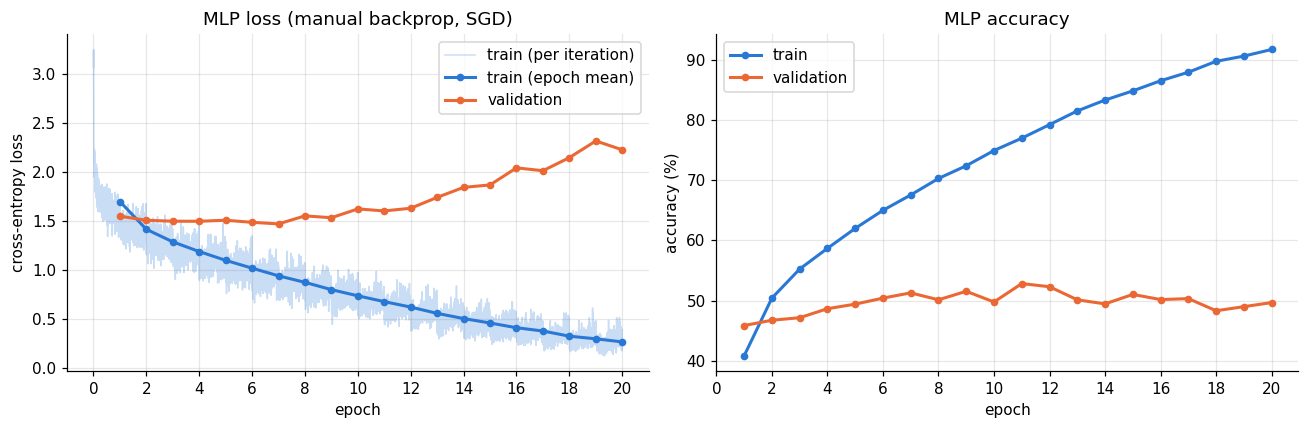

In [8]:
iters_per_epoch = len(train_loader)
epoch_axis = np.arange(1, epochs + 1)
fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(12, 4))

ax_loss.plot(np.arange(1, len(history['iter_loss']) + 1) / iters_per_epoch, history['iter_loss'],
             color=COLORS[0], alpha=0.25, linewidth=1, label='train (per iteration)')
ax_loss.plot(epoch_axis, history['train_loss'], color=COLORS[0], marker='o', markersize=4, label='train (epoch mean)')
ax_loss.plot(epoch_axis, history['val_loss'], color=COLORS[1], marker='o', markersize=4, label='validation')
ax_loss.set(xlabel='epoch', ylabel='cross-entropy loss', title='MLP loss (manual backprop, SGD)')
ax_loss.legend()

ax_acc.plot(epoch_axis, np.array(history['train_acc']) * 100, color=COLORS[0], marker='o', markersize=4, label='train')
ax_acc.plot(epoch_axis, np.array(history['val_acc']) * 100, color=COLORS[1], marker='o', markersize=4, label='validation')
ax_acc.set(xlabel='epoch', ylabel='accuracy (%)', title='MLP accuracy')
ax_acc.legend()
for ax in (ax_loss, ax_acc):
    ax.set_xticks(np.arange(0, epochs + 1, 2))
plt.tight_layout()
plt.show()

**Interpretation.** The MLP reaches **≈52 % validation accuracy** after 20 epochs, against 10 % for random guessing.

**The curves show overfitting.** Training loss falls steadily from 1.70 to 0.26, and training accuracy reaches ≈92 %. Validation loss is lowest at epoch 6 (≈1.44) and then rises to ≈2.1, while validation accuracy stays flat at 48–52 %. With ≈1.7 M parameters and no weight sharing, the MLP memorises the training images instead of learning features that generalise.

**Validation loss rises while validation accuracy holds.** The network becomes over-confident on the images it still gets wrong, and cross-entropy punishes confident mistakes heavily.

**Flattening also discards the 2-D structure of the image.** The same cat shifted by a few pixels becomes a completely different input vector. This motivates the CNNs in the later tasks.

**The per-iteration loss is noisy** because each SGD step uses a gradient estimated from only 128 images.

### 1(d) Per-layer gradient norms in a 10-layer MLP

Ten Linear layers (3072 → 256 × 9 → 10) with the **same** Kaiming initial weights; only the activation differs. One forward/backward pass at initialization on a batch of 512 training images gives $\lVert \partial L/\partial W_l \rVert$ for each layer $l$.

layer       Sigmoid        ReLU
1          1.51e-04    3.00e+00
2          1.50e-04    1.04e+00
3          4.75e-04    1.32e+00
4          1.40e-03    1.39e+00
5          4.29e-03    1.75e+00
6          1.32e-02    1.93e+00
7          4.43e-02    2.19e+00
8          1.32e-01    2.69e+00
9          4.68e-01    2.90e+00
10         1.46e+00    3.07e+00
Sigmoid: layer 1 / layer 10 gradient-norm ratio = 1.0e-04
ReLU: layer 1 / layer 10 gradient-norm ratio = 9.8e-01


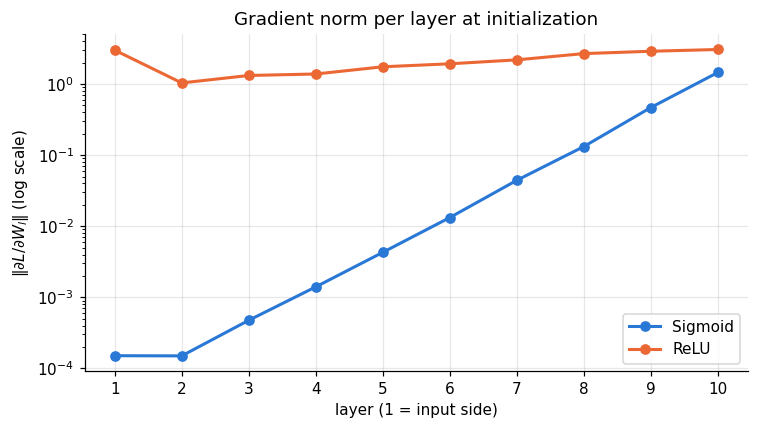

In [9]:
def layer_gradient_norms(activation, x, labels):
    torch.manual_seed(SEED)                                             # identical initial weights for both runs
    deep_mlp = MLP([3072] + [256] * 9 + [10], activation=activation, device=device)
    deep_mlp.loss(x, labels)
    deep_mlp.backward()
    return [layer.dW.norm().item() for layer in deep_mlp.linear_layers()]


images, labels = next(iter(DataLoader(train_dataset, batch_size=512, shuffle=False)))
x_batch, y_batch = images.view(len(images), -1).to(device), labels.to(device)
grad_norms = {'Sigmoid': layer_gradient_norms(Sigmoid, x_batch, y_batch),
              'ReLU': layer_gradient_norms(ReLU, x_batch, y_batch)}

print(f"{'layer':<7}{'Sigmoid':>12}{'ReLU':>12}")
for l, (s, r) in enumerate(zip(grad_norms['Sigmoid'], grad_norms['ReLU']), start=1):
    print(f'{l:<7}{s:>12.2e}{r:>12.2e}')
for name, norms in grad_norms.items():
    print(f'{name}: layer 1 / layer 10 gradient-norm ratio = {norms[0] / norms[-1]:.1e}')

layer_axis = np.arange(1, 11)
plt.figure(figsize=(7, 4))
for color, (name, norms) in zip(COLORS, grad_norms.items()):
    plt.semilogy(layer_axis, norms, color=color, marker='o', markersize=6, label=name)
plt.xticks(layer_axis)
plt.xlabel('layer (1 = input side)')
plt.ylabel(r'$\|\partial L / \partial W_l\|$ (log scale)')
plt.title('Gradient norm per layer at initialization')
plt.legend()
plt.tight_layout()
plt.show()

**Interpretation.**

**Sigmoid: vanishing gradients.** The gradient norm shrinks by about 3× per layer moving back toward the input. Layer 1 receives only about $10^{-4}$ of layer 10's gradient, so the early layers would barely change during training. The cause is that every backward step multiplies by $\sigma'(z) = \sigma(1-\sigma) \le 0.25$. With Kaiming weights the per-layer gain is about $\sqrt{2\,\mathbb{E}[\sigma'^2]} \approx 0.3$, and nine steps give $0.3^9 \approx 2\times10^{-5}$.

**ReLU: the norm stays flat.** The derivative is exactly 1 on active units and 0 on the roughly half that are inactive. The factor 2 in Kaiming's $\mathrm{Var}(W) = 2/D$ compensates for the switched-off half, so the gain is about $\sqrt{2 \cdot \tfrac12} = 1$. All ten layers stay within the same order of magnitude (1.4–3.3).

**Layer 1 sits above the trend in both curves** because its input is the 3072-dimensional image, which has a larger norm than a 256-unit hidden layer.

This is why deep networks use ReLU with Kaiming initialisation, and why very deep networks also need shortcuts (Task 3(b)).

## Task 2: Optimizers

Each optimizer turns the gradient $g = \nabla_\theta L$ into a parameter update:

| Optimizer | State it keeps | Update |
|---|---|---|
| SGD | none | $\theta \leftarrow \theta - \eta\, g$ |
| SGD + momentum | velocity $v$ | $v \leftarrow \mu v + g, \quad \theta \leftarrow \theta - \eta\, v$ |
| Adam | 1st moment $m$, 2nd moment $s$, step $t$ | $m \leftarrow \beta_1 m + (1-\beta_1) g, \quad s \leftarrow \beta_2 s + (1-\beta_2) g^2$ |
| | | $\hat m = \dfrac{m}{1-\beta_1^t}, \quad \hat s = \dfrac{s}{1-\beta_2^t}, \quad \theta \leftarrow \theta - \eta\, \dfrac{\hat m}{\sqrt{\hat s} + \epsilon}$ |

- **Momentum** is a heavy ball. $v$ is a running sum of past gradients, so steps that agree add up and steps that flip sign cancel.
- **Adam** gives every parameter its own step size. It divides the averaged gradient by its recent RMS, so steep and flat directions move at similar speeds.
- **Bias correction:** $m$ and $s$ start at 0, so early averages are too small. At $t=1$, $m = 0.1\,g$, and dividing by $1-\beta_1^1 = 0.1$ restores $\hat m = g$.

### 2(a) Custom optimizers and a check against PyTorch

Both classes subclass `torch.optim.Optimizer`, which stores the hyper-parameters in `param_groups` and per-parameter buffers in `self.state`. `MySGD` with `momentum=0` is plain SGD. The velocity buffer starts at $v = g$, which is PyTorch's convention.

In [10]:
class MySGD(torch.optim.Optimizer):
    def __init__(self, params, lr, momentum=0.0):
        super().__init__(params, dict(lr=lr, momentum=momentum))

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()
        for group in self.param_groups:
            for p in group['params']:
                if p.grad is None:
                    continue
                update = p.grad
                if group['momentum'] != 0:
                    state = self.state[p]
                    if 'velocity' not in state:
                        state['velocity'] = p.grad.clone()                     # v_1 = g_1
                    else:
                        state['velocity'].mul_(group['momentum']).add_(p.grad)  # v = mu*v + g
                    update = state['velocity']
                p.add_(update, alpha=-group['lr'])                              # theta -= lr * update
        return loss


class MyAdam(torch.optim.Optimizer):
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8):
        super().__init__(params, dict(lr=lr, betas=betas, eps=eps))

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()
        for group in self.param_groups:
            beta1, beta2 = group['betas']
            for p in group['params']:
                if p.grad is None:
                    continue
                state = self.state[p]
                if not state:
                    state['t'] = 0
                    state['m'] = torch.zeros_like(p)                            # 1st moment: mean of g
                    state['s'] = torch.zeros_like(p)                            # 2nd moment: mean of g^2
                state['t'] += 1
                t, m, s = state['t'], state['m'], state['s']
                m.mul_(beta1).add_(p.grad, alpha=1 - beta1)
                s.mul_(beta2).addcmul_(p.grad, p.grad, value=1 - beta2)
                m_hat = m / (1 - beta1 ** t)                                    # bias correction
                s_hat = s / (1 - beta2 ** t)
                p.addcdiv_(m_hat, s_hat.sqrt().add_(group['eps']), value=-group['lr'])
        return loss

In [11]:
def compare_with_torch(make_mine, make_reference, steps=50):
    torch.manual_seed(SEED)
    model_mine = nn.Sequential(nn.Linear(20, 32), nn.ReLU(), nn.Linear(32, 10))
    model_ref = copy.deepcopy(model_mine)                                       # identical starting weights
    initial = [p.detach().clone() for p in model_mine.parameters()]
    opt_mine, opt_ref = make_mine(model_mine.parameters()), make_reference(model_ref.parameters())
    data = torch.Generator().manual_seed(SEED)
    for _ in range(steps):
        x, y = torch.randn(16, 20, generator=data), torch.randint(0, 10, (16,), generator=data)
        for model, opt in ((model_mine, opt_mine), (model_ref, opt_ref)):
            opt.zero_grad()
            F.cross_entropy(model(x), y).backward()
            opt.step()
    pairs = list(zip(model_mine.parameters(), model_ref.parameters()))
    max_diff = max((a - b).abs().max().item() for a, b in pairs)
    moved = max((a - p0).abs().max().item() for (a, _), p0 in zip(pairs, initial))
    return moved, max_diff, all(torch.allclose(a, b) for a, b in pairs)


checks = {
    'SGD (momentum 0)':   (lambda ps: MySGD(ps, lr=0.1),               lambda ps: torch.optim.SGD(ps, lr=0.1)),
    'SGD (momentum 0.9)': (lambda ps: MySGD(ps, lr=0.05, momentum=0.9), lambda ps: torch.optim.SGD(ps, lr=0.05, momentum=0.9)),
    'Adam':               (lambda ps: MyAdam(ps, lr=1e-3),              lambda ps: torch.optim.Adam(ps, lr=1e-3)),
}
print(f"{'optimizer':<20}{'max |θ - θ0|':>14}{'max |mine - torch|':>21}{'allclose':>10}")
for name, (mine, reference) in checks.items():
    moved, max_diff, match = compare_with_torch(mine, reference)
    print(f'{name:<20}{moved:>14.4f}{max_diff:>21.2e}{str(match):>10}')

optimizer             max |θ - θ0|   max |mine - torch|  allclose
SGD (momentum 0)            0.1032             0.00e+00      True
SGD (momentum 0.9)          0.2301             0.00e+00      True
Adam                        0.0281             4.47e-08      True


**Interpretation.** After 50 steps on identical models and batches, all three custom optimizers match PyTorch, and `torch.allclose` is True for each. The parameters moved by up to 0.03–0.23, so the match is not trivial.

- **Both SGD variants are bit-for-bit identical** (difference 0), because they perform the same operations in the same order.
- **Adam differs by about $3\times10^{-8}$**, which is float32 rounding. PyTorch evaluates the same formula in a rearranged order: it divides $\sqrt{s}$ by $\sqrt{1-\beta_2^t}$ inside the denominator instead of forming $\hat s$ first. That changes the last bits, not the mathematics.

### 2(b) Trajectories on an ill-conditioned quadratic

$f(x, y) = \tfrac12(x^2 + 50y^2)$ has gradient $(x,\, 50y)$, so the curvature along $y$ is 50 times that along $x$ (condition number 50). Plain gradient descent is stable only if $\eta < 2/50 = 0.04$. All runs start at $(-10, 1)$ and take 100 steps:

- SGD and momentum both use $\eta = 0.035$, close to SGD's stability limit, with $\mu = 0.9$ for momentum.
- Adam uses $\eta = 0.5$. Its step is about $\eta$ per coordinate whatever the gradient's scale, so its learning rate is not comparable to SGD's.

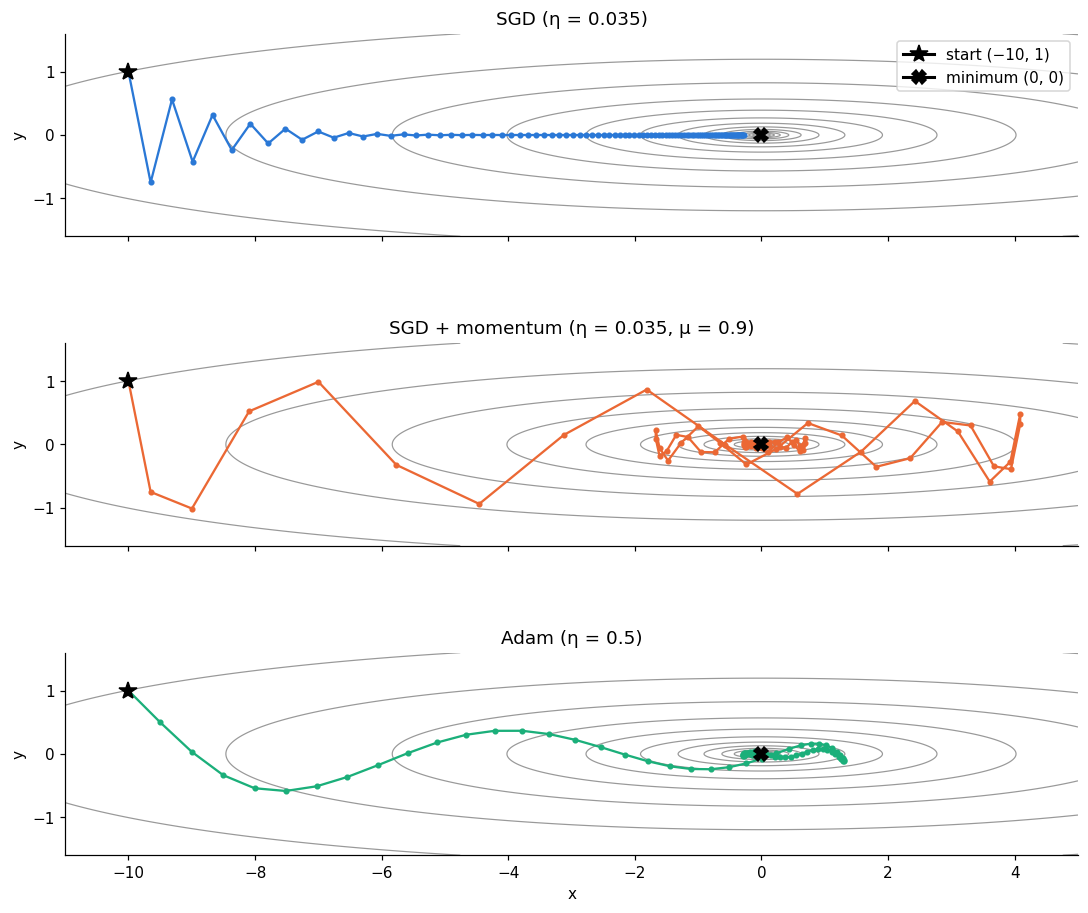

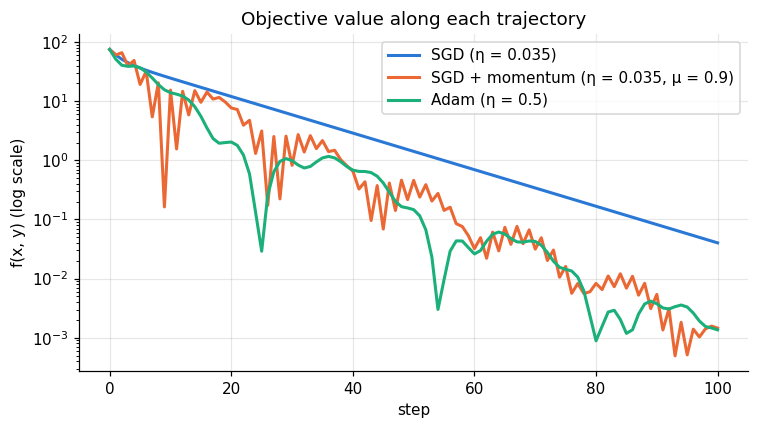

SGD (η = 0.035)                        final point (-0.2836, +0.0000), f = 4.02e-02
SGD + momentum (η = 0.035, μ = 0.9)    final point (-0.0451, +0.0042), f = 1.45e-03
Adam (η = 0.5)                         final point (+0.0421, -0.0043), f = 1.36e-03


In [12]:
def quadratic(p):
    return 0.5 * (p[0] ** 2 + 50 * p[1] ** 2)


def run_trajectory(make_optimizer, start=(-10.0, 1.0), steps=100):
    p = torch.tensor(start, dtype=torch.float64, requires_grad=True)
    optimizer = make_optimizer([p])
    path = [p.detach().clone()]
    for _ in range(steps):
        optimizer.zero_grad()
        quadratic(p).backward()
        optimizer.step()
        path.append(p.detach().clone())
    return torch.stack(path).numpy()


trajectories = {
    'SGD (η = 0.035)':                 run_trajectory(lambda ps: MySGD(ps, lr=0.035)),
    'SGD + momentum (η = 0.035, μ = 0.9)': run_trajectory(lambda ps: MySGD(ps, lr=0.035, momentum=0.9)),
    'Adam (η = 0.5)':                  run_trajectory(lambda ps: MyAdam(ps, lr=0.5)),
}

gx, gy = np.meshgrid(np.linspace(-11, 5, 400), np.linspace(-1.6, 1.6, 400))
gf = 0.5 * (gx ** 2 + 50 * gy ** 2)
fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True)
for ax, color, (name, path) in zip(axes, COLORS, trajectories.items()):
    ax.contour(gx, gy, gf, levels=np.logspace(-2, 2.2, 14), colors='0.6', linewidths=0.8)
    ax.plot(path[:, 0], path[:, 1], color=color, marker='o', markersize=3, linewidth=1.5)
    ax.plot(*path[0], marker='*', color='black', markersize=12, label='start (−10, 1)')
    ax.plot(0, 0, marker='X', color='black', markersize=9, label='minimum (0, 0)')
    ax.set(ylabel='y', title=name, aspect='equal')
    ax.grid(False)
axes[0].legend(loc='upper right')
axes[-1].set_xlabel('x')
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
for color, (name, path) in zip(COLORS, trajectories.items()):
    plt.semilogy(0.5 * (path[:, 0] ** 2 + 50 * path[:, 1] ** 2), color=color, label=name)
plt.xlabel('step')
plt.ylabel('f(x, y) (log scale)')
plt.title('Objective value along each trajectory')
plt.legend()
plt.tight_layout()
plt.show()

for name, path in trajectories.items():
    print(f'{name:<38} final point ({path[-1, 0]:+.4f}, {path[-1, 1]:+.4f}), f = {quadratic(path[-1]):.2e}')

**Interpretation.**

**SGD.** The $y$ direction is 50 times steeper than $x$, and $\eta \cdot 50 = 1.75 > 1$. So every step overshoots in $y$: $y$ is multiplied by $1 - 1.75 = -0.75$, which gives the zig-zag across the valley. Along the shallow $x$ direction, $x$ is multiplied by only $1 - 0.035 = 0.965$ per step, so it crawls: $x = -4.9$ after 20 steps and still $-0.28$ after 100. $\eta$ cannot be raised to speed up $x$, because $\eta > 0.04$ makes $y$ diverge. This is the core problem of ill-conditioning: the steepest direction caps the step size, and the flattest direction then sets the speed.

**SGD + momentum.** The $x$-gradient always points the same way, so the velocity builds up along the valley and the ball reaches $x = 0$ in 10 steps. The alternating $y$-gradients partly cancel. With $\mu = 0.9$ the motion is under-damped: like a heavy ball, it overshoots to $x \approx +4.1$ and spirals in. It still ends about 30 times lower than SGD ($f = 1.5\times10^{-3}$ against $4.0\times10^{-2}$).

**Adam.** It divides each gradient component by its own RMS, so it steps about $\eta$ in both $x$ and $y$ whatever the 50 times curvature difference. Its first steps go diagonally, the $y$ zig-zag disappears, and the path is smooth. It reaches $f \approx 1.4\times10^{-3}$, like momentum. Near the minimum, $\hat m/\sqrt{\hat s}$ stays close to $\pm1$ even though the gradient is tiny, so the step does not shrink. Adam therefore hovers around the minimum (the bumps in the $f$ curve) unless the learning rate is decayed.

### 2(c) Optimizer comparison on a small CNN

**Network.** Three blocks of conv 3×3 → ReLU → max-pool (32 → 64 → 128 channels), then FC 2048 → 128 → 10, about 357k parameters. It has no batch norm, so the effect of the learning rate is not hidden.

**Learning rates.** Each optimizer runs at three rates, spaced 10× apart:
- SGD and SGD + momentum: {0.001, 0.01, 0.1}
- Adam: {0.0001, 0.001, 0.01}

**Fair comparison.** Every run uses the same seed, so the initial weights and batch order are identical. The batch size is 128.

**Data.** The normalized images are loaded once into a tensor on the device. This is much faster than a `DataLoader` for small images on a GPU.

**`QUICK` mode.** On a CPU-only machine `QUICK` is switched on automatically, giving short debug runs on 5k images. The reported results come from a full run on a Colab T4 (`QUICK = False`).

In [13]:
QUICK = device.type == 'cpu'          # laptop CPU: short debug runs; GPU (Colab T4): the full experiment
EPOCHS = 2 if QUICK else 15
TRAIN_SUBSET = 5000 if QUICK else None
if QUICK:
    print('QUICK mode: debug run only, results are not meaningful')


def load_split(indices):
    images = torch.tensor(train_dataset_full.data[indices]).permute(0, 3, 1, 2).float().div(255)
    images = (images - mean.view(1, 3, 1, 1)) / std.view(1, 3, 1, 1)          # same as ToTensor + Normalize
    labels = torch.tensor(train_dataset_full.targets)[indices]
    return images.to(device), labels.to(device)


train_x, train_y = load_split(train_indices[:TRAIN_SUBSET])
val_x, val_y = load_split(val_indices)
assert torch.allclose(train_x[0].cpu(), train_dataset[0][0], atol=1e-6)        # matches the DataLoader pipeline
print('train', tuple(train_x.shape), 'validation', tuple(val_x.shape))


def iterate_minibatches(x, y, batch_size, shuffle=False):
    order = torch.randperm(len(x), device=x.device) if shuffle else torch.arange(len(x), device=x.device)
    for start in range(0, len(x), batch_size):
        idx = order[start:start + batch_size]
        yield x[idx], y[idx]


@torch.no_grad()
def evaluate(model, x, y, batch_size=1000):
    model.eval()
    loss_sum, correct = 0.0, 0
    for xb, yb in iterate_minibatches(x, y, batch_size):
        logits = model(xb)
        loss_sum += F.cross_entropy(logits, yb, reduction='sum').item()
        correct += (logits.argmax(dim=1) == yb).sum().item()
    return loss_sum / len(x), correct / len(x)


def train(model, optimizer, epochs, train_x, train_y, val_x, val_y, batch_size=128):
    history = {'iter_loss': [], 'train_loss': [], 'val_loss': [], 'val_acc': []}
    for epoch in range(epochs):
        model.train()
        losses = []
        for xb, yb in iterate_minibatches(train_x, train_y, batch_size, shuffle=True):
            loss = F.cross_entropy(model(xb), yb)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            losses.append(loss.detach())
        losses = torch.stack(losses).cpu()
        val_loss, val_acc = evaluate(model, val_x, val_y)
        history['iter_loss'] += losses.tolist()
        history['train_loss'].append(losses.mean().item())
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)
        if not torch.isfinite(losses).all():                                    # diverged: stop this run
            break
    return history


class SmallCNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),        # 32x32 -> 16x16
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),       # 16x16 -> 8x8
            nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),      # 8x8 -> 4x4
        )
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(128 * 4 * 4, 128), nn.ReLU(), nn.Linear(128, num_classes))

    def forward(self, x):
        return self.classifier(self.features(x))


print('SmallCNN parameters:', sum(p.numel() for p in SmallCNN().parameters()))

train (45000, 3, 32, 32) validation (5000, 3, 32, 32)
SmallCNN parameters: 356810


In [14]:
OPTIMIZERS = {
    'SGD':            (lambda params, lr: MySGD(params, lr=lr),               [0.001, 0.01, 0.1]),
    'SGD + momentum': (lambda params, lr: MySGD(params, lr=lr, momentum=0.9), [0.001, 0.01, 0.1]),
    'Adam':           (lambda params, lr: MyAdam(params, lr=lr),              [0.0001, 0.001, 0.01]),
}
results = {}
for name, (make_optimizer, learning_rates) in OPTIMIZERS.items():
    for lr in learning_rates:
        torch.manual_seed(SEED)                                                 # same init and batch order for every run
        model = SmallCNN().to(device)
        start = time.time()
        history = train(model, make_optimizer(model.parameters(), lr), EPOCHS, train_x, train_y, val_x, val_y)
        results[(name, lr)] = history
        print(f"{name:<15} lr = {lr:<7g} | final train loss {history['train_loss'][-1]:7.3f} "
              f"| final val acc {history['val_acc'][-1]:6.2%} (best {max(history['val_acc']):6.2%}) | {time.time() - start:5.0f} s")

SGD             lr = 0.001   | final train loss   2.006 | final val acc 29.74% (best 29.74%) |    32 s
SGD             lr = 0.01    | final train loss   1.061 | final val acc 61.36% (best 61.36%) |    31 s
SGD             lr = 0.1     | final train loss   0.151 | final val acc 73.98% (best 74.20%) |    31 s
SGD + momentum  lr = 0.001   | final train loss   1.034 | final val acc 61.68% (best 61.68%) |    32 s
SGD + momentum  lr = 0.01    | final train loss   0.143 | final val acc 76.68% (best 76.68%) |    32 s
SGD + momentum  lr = 0.1     | final train loss   1.367 | final val acc 45.02% (best 60.56%) |    33 s
Adam            lr = 0.0001  | final train loss   0.919 | final val acc 64.68% (best 64.84%) |    34 s
Adam            lr = 0.001   | final train loss   0.115 | final val acc 75.04% (best 75.66%) |    34 s
Adam            lr = 0.01    | final train loss   1.051 | final val acc 58.72% (best 58.72%) |    33 s


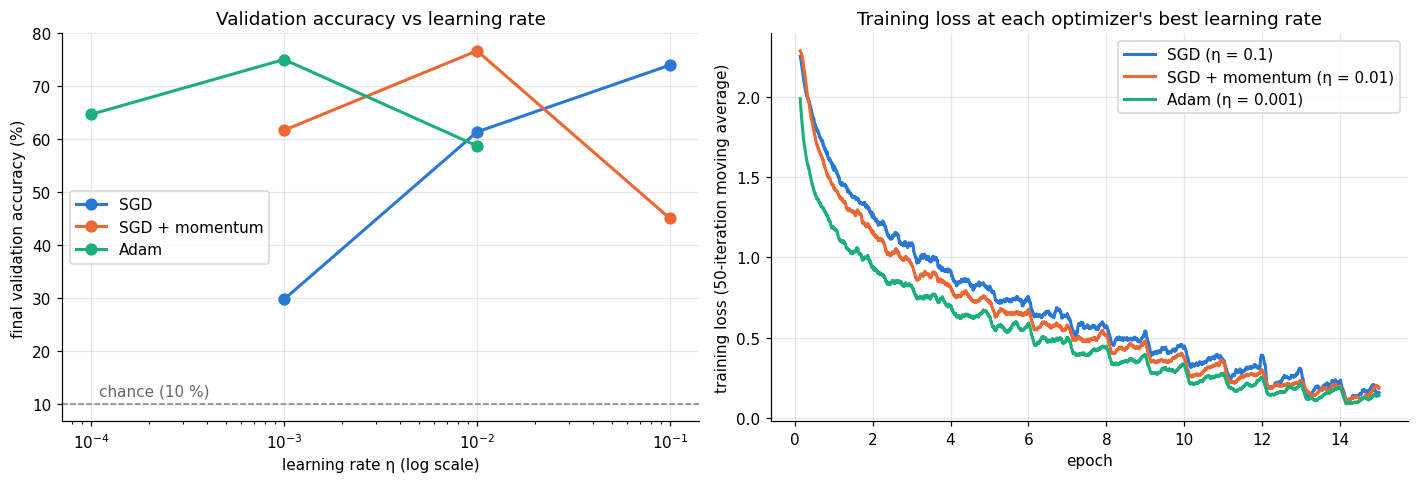

optimizer             lr  val acc      lr  val acc      lr  val acc
SGD                0.001   29.74%    0.01   61.36%     0.1   73.98%   best η = 0.1
SGD + momentum     0.001   61.68%    0.01   76.68%     0.1   45.02%   best η = 0.01
Adam              0.0001   64.68%   0.001   75.04%    0.01   58.72%   best η = 0.001


In [15]:
fig, (ax_acc, ax_loss) = plt.subplots(1, 2, figsize=(13, 4.5))
best_lr = {}
for color, (name, (_, learning_rates)) in zip(COLORS, OPTIMIZERS.items()):
    accs = [results[(name, lr)]['val_acc'][-1] * 100 for lr in learning_rates]
    best_lr[name] = learning_rates[int(np.argmax(accs))]
    ax_acc.semilogx(learning_rates, accs, color=color, marker='o', markersize=7, label=name)

    iter_loss = np.array(results[(name, best_lr[name])]['iter_loss'])
    window = 50
    smooth = np.convolve(iter_loss, np.ones(window) / window, mode='valid')
    iters_per_epoch = int(np.ceil(len(train_x) / 128))
    ax_loss.plot((np.arange(len(smooth)) + window) / iters_per_epoch, smooth, color=color,
                 label=f'{name} (η = {best_lr[name]:g})')

ax_acc.axhline(10, color='0.5', linestyle='--', linewidth=1)
ax_acc.text(1.1e-4, 11.5, 'chance (10 %)', color='0.4')
ax_acc.set(xlabel='learning rate η (log scale)', ylabel='final validation accuracy (%)', title='Validation accuracy vs learning rate')
ax_acc.legend()
ax_loss.set(xlabel='epoch', ylabel='training loss (50-iteration moving average)', title='Training loss at each optimizer\'s best learning rate')
ax_loss.legend()
plt.tight_layout()
plt.show()

print(f"{'optimizer':<16}" + ''.join(f'{"lr":>8}{"val acc":>9}' for _ in range(3)))
for name, (_, learning_rates) in OPTIMIZERS.items():
    row = ''.join(f"{lr:>8g}{results[(name, lr)]['val_acc'][-1]:>9.2%}" for lr in learning_rates)
    print(f'{name:<16}{row}   best η = {best_lr[name]:g}')

**Interpretation.** *To be written from the full run on a Colab T4 (`QUICK = False`). The QUICK numbers on a laptop are debug values only.*